# 統計 ― stats モジュール

## この章で学ぶこと

データのばらつきを扱うとき、平均や分散だけでなく、分布の形を考えることがあります。`stats` モジュールには、いろいろな確率分布を表すオブジェクトが入っています。確率変数は確率論の用語で、Python の変数とは別のものです。連続分布は `rv_continuous`、離散分布は `rv_discrete` の派生クラスです。

* 確率変数のメソッド(`pdf`、`cdf`、`rvs`、`fit`)
* 乱数とヒストグラムで、分布の式を確かめる
* 離散分布を自分で定義する
* 中心極限定理とカーネル密度推定
* 二項分布、ポアソン分布、ガンマ分布
* t 検定とカイ二乗検定

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
import helper.magics
from scipy import stats

## 連続確率分布

`stats` モジュールにある連続分布のオブジェクトは、次のようにして一覧できます。

In [2]:
from scipy import stats

%col 4 [k for k, v in stats.__dict__.items() if isinstance(v, stats.rv_continuous)]

['ksone',                 'kstwo',                 'kstwobign',             'norm',                 
 'alpha',                 'anglit',                'arcsine',               'beta',                 
 'betaprime',             'bradford',              'burr',                  'burr12',               
 'fisk',                  'cauchy',                'chi',                   'chi2',                 
 'cosine',                'dgamma',                'dpareto_lognorm',       'dweibull',             
 'expon',                 'exponnorm',             'exponweib',             'exponpow',             
 'fatiguelife',           'foldcauchy',            'f',                     'foldnorm',             
 'weibull_min',           'truncweibull_min',      'weibull_max',           'genlogistic',          
 'genpareto',             'genexpon',              'genextreme',            'gamma',                
 'erlang',                'gengamma',              'genhalflogistic',       'genhyperbolic'

確率変数のオブジェクトには、次のメソッドがあります。

* `rvs`：乱数を返す。`size` で個数を指定する。
* `pdf`：確率密度関数。
* `cdf`：累積分布関数。確率密度関数を積分したもの。
* `sf`：生存関数。値は `1 - cdf(t)`。
* `ppf`：累積分布関数の逆関数。
* `stats`：期待値と分散を返す。
* `fit`：サンプルに合う分布のパラメータを推定する。

例として、正規分布で試します。引数なしで呼ぶと、平均 0、分散 1 の標準正規分布になります。

In [3]:
stats.norm.stats()

(np.float64(0.0), np.float64(1.0))

`norm` は関数のように呼べます。`loc` が位置(平均)、`scale` が尺度(標準偏差)です。標準偏差が 2 なら、分散は 4 になります。

In [4]:
X = stats.norm(loc=1.0, scale=2.0)
X.stats()

(np.float64(1.0), np.float64(4.0))

`X.rvs()` で乱数を 1 万個作り、NumPy の `mean()` と `var()` で平均と分散を計算します。値は、確率変数の期待値と分散に近くなります。

In [5]:
x = X.rvs(size=10000)  # 確率変数から10000個の値を取得
np.mean(x), np.var(x)  # 期待値と分散

(np.float64(0.9992448974931074), np.float64(4.009701025456197))

`fit()` を使うと、サンプルに合うパラメータを推定できます。戻り値は平均と標準偏差です。

In [6]:
stats.norm.fit(x)  # ランダムシーケンスの期待値と標準偏差を取得

(np.float64(0.9992448974931074), np.float64(2.002423787677373))

次に、乱数のヒストグラムと、確率変数の確率密度関数・累積分布関数を比べます。

❶ `histogram()` で、`x` の値を 100 の区間に分けて数えます。`density=True` にすると、度数が確率密度になるので、`pdf` と比べられます。❷ `t` は区間の境界で、長さは 101 です。これを各区間の中間の値に直してから、`X.pdf(t)` と `X.cdf(t)` を計算します。❸ サンプルの累積分布は、各区間の確率密度に区間の幅を掛けて足します。

In [7]:
pdf, t = np.histogram(x, bins=100, density=True)  #❶
t = (t[:-1] + t[1:]) * 0.5  #❷
cdf = np.cumsum(pdf) * (t[1] - t[0])  #❸
p_error = pdf - X.pdf(t)
c_error = cdf - X.cdf(t)
print(
    "max pdf error: {:6.3f}, max cdf error: {:6.3f}".format(
        np.abs(p_error).max(), np.abs(c_error).max()
    )
)

max pdf error:  0.021, max cdf error:  0.020


次の図の左は、確率密度関数とヒストグラムです。2 つはほぼ重なっています。右は、累積分布関数と、ヒストグラムから計算した累積分布です。

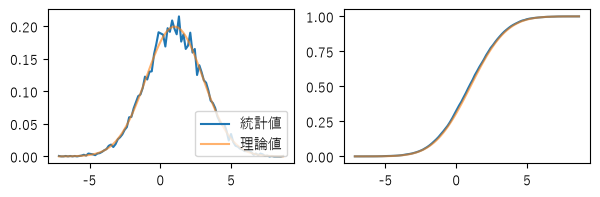

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 2))
ax1.plot(t, pdf, label="統計値")
ax1.plot(t, X.pdf(t), label="理論値", alpha=0.6)
ax1.legend(loc="lower right")
ax2.plot(t, cdf)
ax2.plot(t, X.cdf(t), alpha=0.6);

分布によっては、`loc` と `scale` のほかに形状パラメータが要ります。例えばガンマ分布は、独立なランダム事象が $k$ 回起こるまでの時間を表し、$k$ が形状パラメータです。$k=1$ と $k=2$ の場合の期待値と分散を計算します。

In [9]:
print(stats.gamma.stats(1.0))
print(stats.gamma.stats(2.0))

(np.float64(1.0), np.float64(1.0))
(np.float64(2.0), np.float64(2.0))


尺度パラメータ $\theta$ は、事象の起こる頻度に関係します。`scale` で指定します。

In [10]:
stats.gamma.stats(2.0, scale=2)

(np.float64(4.0), np.float64(8.0))

ガンマ分布の期待値は $k \theta$、分散は $k \theta^2$ です。上の結果が、この式になっていることを確かめてください。

形状パラメータがある分布では、`rvs()` や `pdf()` にも形状パラメータを渡します。次のコードは、$k=2$、$\theta=2$ のガンマ分布から乱数を 4 個作ります。

In [11]:
x = stats.gamma.rvs(2, scale=2, size=4)
x

array([ 0.86890721, 11.23831336, 11.73116186,  3.40416741])

`pdf()` で、この 4 個の値の確率密度を計算します。

In [12]:
stats.gamma.pdf(x, 2, scale=2)

array([0.14068008, 0.0101923 , 0.00831556, 0.15514771])

形状パラメータと尺度パラメータを固定した確率変数を作って、その `pdf()` を呼ぶこともできます。

In [13]:
X = stats.gamma(2, scale=2)
X.pdf(x)

array([0.14068008, 0.0101923 , 0.00831556, 0.15514771])

## 離散確率分布

値が飛び飛びになる分布を、離散確率分布と呼びます。サイコロの目は 1 から 6 の整数なので、離散分布です。離散分布は、確率質量関数(PMF)で表します。

`stats` モジュールの離散分布は、`rv_discrete` クラスから派生しています。このクラスを使えば、自分で分布を作れます。例えば、いびつなサイコロがあり、面ごとに確率が違うとします。出る目を配列 `x`、その確率を配列 `p` に入れます。

In [14]:
x = list(range(1, 7))
p = [0.4, 0.2, 0.1, 0.1, 0.1, 0.1]

このサイコロを表す確率変数 `dice` を作り、20 回振った結果を出します。

In [15]:
dice = stats.rv_discrete(values=(x, p))
dice.rvs(size=20)

array([1, 1, 5, 4, 1, 1, 2, 1, 5, 4, 1, 6, 1, 1, 1, 6, 2, 1, 6, 6])

次に、中心極限定理を確かめます。独立な確率変数をたくさん足すと、その平均の分布は正規分布に近づく、という定理です。

このサイコロを 50 回振り、その平均を計算します。1 回ごとの出目は独立なので、50 回の平均は「多くの独立な確率変数の平均」と見なせます。`rvs()` で形状 `(20000, 50)` の乱数を作り、行ごとの平均を求めます。

In [16]:
np.random.seed(42)
samples = dice.rvs(size=(20000, 50))
samples_mean = np.mean(samples, axis=1)

## カーネル密度推定

サイコロの目は離散的なので、その平均も離散的になります。ヒストグラムにすると、同じ区間に多くの値が集まり、ぎざぎざになります。なめらかな密度を見たいときは、`gaussian_kde()` でカーネル密度推定を行います。

次の図では、ヒストグラムはばらついていますが、カーネル密度推定の曲線は、当てはめた正規分布に近くなっています。中心極限定理が確かめられたことになります。

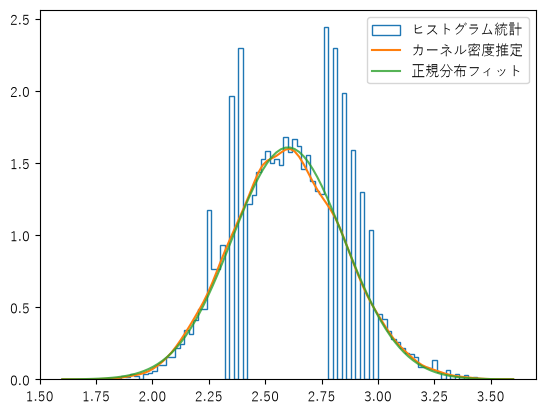

In [17]:
from scipy.stats import gaussian_kde

_, bins, step = plt.hist(
    samples_mean, bins=100, density=True, histtype="step", label="ヒストグラム統計"
)
kde = gaussian_kde(samples_mean)
x = np.linspace(bins[0], bins[-1], 100)
plt.plot(x, kde(x), label="カーネル密度推定")
mean, std = stats.norm.fit(samples_mean)
plt.plot(x, stats.norm(mean, std).pdf(x), alpha=0.8, label="正規分布フィット")
plt.legend();

カーネル密度推定は、各データ点にカーネル関数の曲線を置き、それらを足し合わせたものです。`gaussian_kde()` のカーネルはガウス曲線で、`bw_method` がその幅を決めます。`bw_method` には次の値を指定できます。

* `'scott'` か `'silverman'`：データの数と次元から、式で幅を決める。
* 関数：呼び出して幅を計算する。引数は `gaussian_kde` オブジェクト。
* 数値：その値を幅として使う。

次の図は、幅による違いです。幅が大きいほど曲線はなめらかになります。幅が小さいと 3 つの点のピークが見えますが、幅を大きくすると 1 つのピークにまとまります。

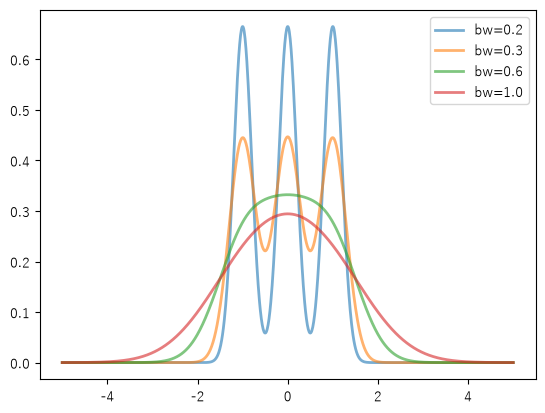

In [18]:
for bw in [0.2, 0.3, 0.6, 1.0]:
    kde = stats.gaussian_kde([-1, 0, 1], bw_method=bw)
    x = np.linspace(-5, 5, 1000)
    y = kde(x)
    plt.plot(x, y, lw=2, label="bw={}".format(bw), alpha=0.6)
plt.legend(loc="best");

## 二項分布、ポアソン分布、ガンマ分布

二項分布、ポアソン分布、ガンマ分布を、乱数で確かめます。

二項分布は、結果が 2 通りしかない実験を $n$ 回行い、$k$ 回成功する確率を表します。成功の確率を $p$ とすると、確率質量関数は次の式です。

$$f(k;n,p) = \frac{n!}{k!(n-k)!} p^k(1-p)^{n-k}$$

例えば、サイコロを 5 回振って 3 回 6 が出る確率を計算します。1 回で 6 が出る確率は $p=1/6$、回数は $n=5$ です。`pmf()` の第 1 引数が確率変数の値で、そのあとに $n$ と $p$ を渡します。

In [19]:
stats.binom.pmf(range(6), 5, 1 / 6.0)

array([4.01877572e-01, 4.01877572e-01, 1.60751029e-01, 3.21502058e-02,
       3.21502058e-03, 1.28600823e-04])

6 が 0 回の確率は 40.2%、1 回の確率も 40.2%、3 回は 3.2% です。

二項分布で $n$ が大きく、$p$ が小さいとき、積 $n p$ がほどよい値なら、成功回数の分布はポアソン分布で近似できます。ポアソン分布は、単位時間あたりにランダムな事象が起こる平均回数を $\lambda$ として、次の式で表されます。

$$f(k;\lambda)=\frac{e^{-\lambda}\lambda^k}{k!}$$

二項分布の $n$ を単位時間の実験回数と考えると、$\lambda = n \cdot p$ です。次のコードは、$n=100$ と $n=1000$ の二項分布を、$\lambda=10$ のポアソン分布と比べます。$n$ が大きいほど、2 つは近くなります。

max err1=0.006755 max err2=0.000630


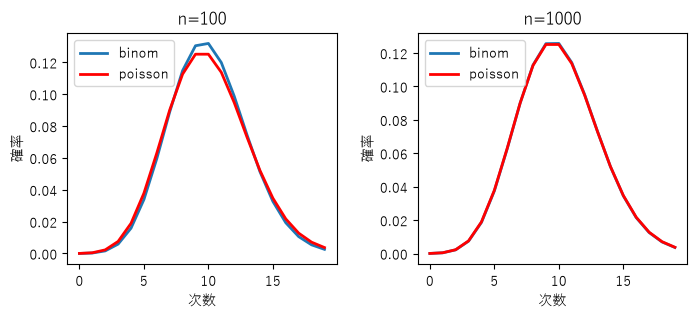

In [20]:
lambda_ = 10.0
x = np.arange(20)

n1, n2 = 100, 1000

y_binom_n1 = stats.binom.pmf(x, n1, lambda_ / n1)
y_binom_n2 = stats.binom.pmf(x, n2, lambda_ / n2)
y_poisson = stats.poisson.pmf(x, lambda_)
print(
    "max err1={:8.6f} max err2={:8.6f}".format(
        np.max(np.abs(y_binom_n1 - y_poisson)), np.max(np.abs(y_binom_n2 - y_poisson))
    )
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.plot(x, y_binom_n1, label="binom", lw=2)
ax1.plot(x, y_poisson, label="poisson", lw=2, color="red")
ax2.plot(x, y_binom_n2, label="binom", lw=2)
ax2.plot(x, y_poisson, label="poisson", lw=2, color="red")
for n, ax in zip((n1, n2), (ax1, ax2)):
    ax.set_xlabel("次数")
    ax.set_ylabel("確率")
    ax.set_title("n={}".format(n))
    ax.legend()
fig.subplots_adjust(wspace=0.3);

ポアソン分布は、一定時間に事象が起こる回数の分布です。施設の利用回数、機械の故障回数、災害の発生回数などに当てはまります。

乱数でポアソン分布を作り、確率質量関数と比べてみます。1 秒あたり平均 10 回($\lambda=10$)の事象を、1000 秒と 50000 秒の間で発生させます。観測時間が長いほど、1 秒あたりの回数の分布はポアソン分布に近づきます。

time=1000, max_error= 0.020
time=50000, max_error= 0.002


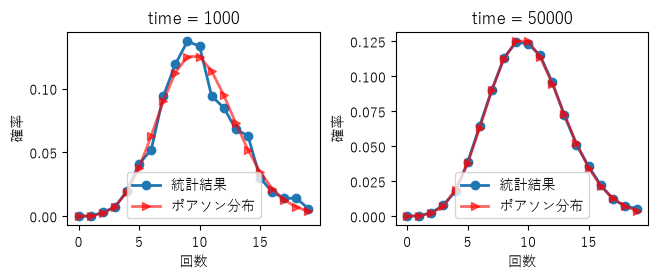

In [21]:
np.random.seed(42)


def sim_poisson(lambda_, time):
    t = np.random.uniform(0, time, size=lambda_ * time)  #❶
    count, time_edges = np.histogram(t, bins=time, range=(0, time))  #❷
    dist, count_edges = np.histogram(count, bins=20, range=(0, 20), density=True)  #❸
    x = count_edges[:-1]
    poisson = stats.poisson.pmf(x, lambda_)
    return x, poisson, dist


lambda_ = 10
times = 1000, 50000
x1, poisson1, dist1 = sim_poisson(lambda_, times[0])
x2, poisson2, dist2 = sim_poisson(lambda_, times[1])
max_error1 = np.max(np.abs(dist1 - poisson1))
max_error2 = np.max(np.abs(dist2 - poisson2))
print("time={}, max_error={:6.3f}".format(times[0], max_error1))
print("time={}, max_error={:6.3f}".format(times[1], max_error2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 2.5))

ax1.plot(x1, dist1, "-o", lw=2, label="統計結果")
ax1.plot(x1, poisson1, "->", lw=2, label="ポアソン分布", color="red", alpha=0.6)
ax2.plot(x2, dist2, "-o", lw=2, label="統計結果")
ax2.plot(x2, poisson2, "->", lw=2, label="ポアソン分布", color="red", alpha=0.6)

for ax, time in zip((ax1, ax2), times):
    ax.set_xlabel("回数")
    ax.set_ylabel("確率")
    ax.set_title("time = {}".format(time))
    ax.legend(loc="lower center")

fig.subplots_adjust(wspace=0.3);

❶ `uniform()` で、0 から `time` までの一様乱数を `lambda_*time` 個作り、事象の発生時刻とします。❷ `histogram()` で、1 秒ごとの事象の回数 `count` を数えます。❸ その回数の分布を、0 から 20 の範囲で集計します。`density=True` にすると、確率質量関数と同じ意味になります。

別の見方もできます。隣り合う事象の間隔や、$k$ 個離れた事象の間隔の分布です。事象の間隔はガンマ分布に従います。間隔は連続の値なので、ガンマ分布は連続分布です。確率密度関数は次のとおりで、$k$ 番目の事象までの待ち時間を表します。$\Gamma(k)$ はガンマ関数で、$k$ が整数なら $k!$ に等しくなります。

$$f(X;k, \lambda)=\frac{X^{(k-1)}\lambda^{k} e^{(-\lambda X)}}{\Gamma(k)}$$

次のコードは、事象の間隔の分布をガンマ分布と比べます。観測時間は 1000 秒で、1 秒あたり平均 10 回です。$k=1$ が隣り合う事象の間隔、$k=2$ が 1 つ飛ばした間隔です。どちらもガンマ分布に従います。

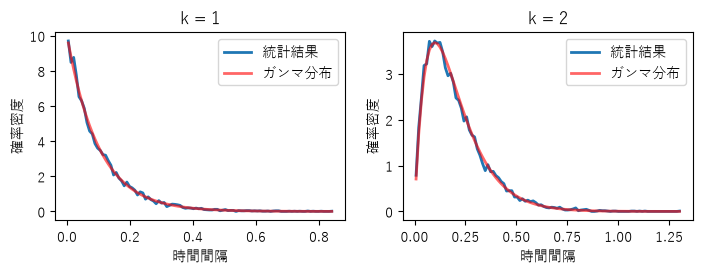

In [22]:
def sim_gamma(lambda_, time, k):
    t = np.random.uniform(0, time, size=lambda_ * time)  #❶
    t.sort()  #❷
    interval = t[k:] - t[:-k]  #❸
    dist, interval_edges = np.histogram(interval, bins=100, density=True)  #❹
    x = (interval_edges[1:] + interval_edges[:-1]) / 2  #❺
    gamma = stats.gamma.pdf(x, k, scale=1.0 / lambda_)  #❺
    return x, gamma, dist


lambda_ = 10.0
time = 1000
ks = 1, 2
x1, gamma1, dist1 = sim_gamma(int(lambda_), time, ks[0])
x2, gamma2, dist2 = sim_gamma(int(lambda_), time, ks[1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 2.5))

ax1.plot(x1, dist1, lw=2, label="統計結果")
ax1.plot(x1, gamma1, lw=2, label="ガンマ分布", color="red", alpha=0.6)
ax2.plot(x2, dist2, lw=2, label="統計結果")
ax2.plot(x2, gamma2, lw=2, label="ガンマ分布", color="red", alpha=0.6)

for ax, k in zip((ax1, ax2), ks):
    ax.set_xlabel("時間間隔")
    ax.set_ylabel("確率密度")
    ax.set_title("k = {}".format(k))
    ax.legend(loc="upper right")

fig.subplots_adjust(0.1, 0.15, 0.95, 0.90, 0.2, 0.1);

❶ 1000 秒の間に、ランダムな時刻で 10000 個の事象を起こします。1 秒あたり平均 10 回です。❷ 間隔を計算するために、時刻を並べ替えます。❸ $k$ 個離れた事象の間隔を計算します。❹ その間隔のヒストグラムを取ります。`density=True` なので、そのまま確率密度と比べられます。❺ `gamma.pdf()` には各区間の中間の値を渡します。第 2 引数が $k$、`scale` が $1/\lambda$ です。

次に、ガンマ分布を使う確率の問題を考えます。A と B の 2 つのバスがあり、平均の発車間隔がそれぞれ 5 分と 10 分です。乗客が駅 S でどちらかに乗るとき、平均の待ち時間は何分でしょう。バスの到着時刻はでたらめだとします。

到着がでたらめなら、単位時間に S に来るバスの本数はポアソン分布、間隔は $k=1$ のガンマ分布に従います。まず乱数で近似し、そのあと式で確かめます。

In [23]:
T = 100000
A_count = T // 5
B_count = T // 10

A_time = np.random.uniform(0, T, A_count)  #❶
B_time = np.random.uniform(0, T, B_count)

bus_time = np.concatenate((A_time, B_time))  #❷
bus_time.sort()

N = 200000
passenger_time = np.random.uniform(bus_time[0], bus_time[-1], N)  #❸

idx = np.searchsorted(bus_time, passenger_time)  #❹
np.mean(bus_time[idx] - passenger_time) * 60  #❺

np.float64(202.33887478797047)

シミュレーションの時間は `T` 分で、その間に A が `A_count` 本、B が `B_count` 本来ます。❶ `uniform()` で、2 路線の到着時刻を作ります。❷ 2 つの時刻をまとめて並べ替えます。

❸ 最初と最後のバスの間に、乗客の到着時刻をランダムに作ります。❹ `searchsorted()` で、乗客の時刻のあとに来るバスの位置を求めます。❺ そのバスの時刻との差が待ち時間なので、平均を取ります。結果は約 200 秒です。

A と B を合わせたバスの平均間隔も 200 秒です。平均間隔より短い待ち時間になりそうな気がしますが、そうはなりません。

In [24]:
np.mean(np.diff(bus_time)) * 60

np.float64(199.99833251643057)

これは観測者バイアスです。間隔が長いほど、その間に駅に来る乗客が多くなるためです。バスが事故で遅れたとき、駅に待っている人が多いのと同じ理屈です。

次の図の上は、青い線がバスの到着、赤い線が乗客の到着です。青い線の間隔が広いほど、赤い線も多くなります。下の図は、横軸がバスの間隔、縦軸がその間隔に現れた乗客の数です。2 つは比例しています。

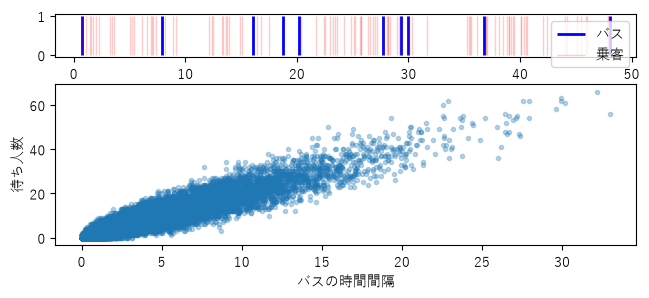

In [25]:
import matplotlib.gridspec as gridspec

plt.figure(figsize=(7.5, 3))

G = gridspec.GridSpec(10, 1)
ax1 = plt.subplot(G[:2, 0])
ax2 = plt.subplot(G[3:, 0])

ax1.vlines(bus_time[:10], 0, 1, lw=2, color="blue", label="バス")
ptime = np.random.uniform(bus_time[0], bus_time[9], 100)
ax1.vlines(ptime, 0, 1, lw=1, color="red", alpha=0.2, label="乗客")
ax1.legend()
count, bins = np.histogram(passenger_time, bins=bus_time)
ax2.plot(np.diff(bins), count, ".", alpha=0.3, rasterized=True)
ax2.set_xlabel("バスの時間間隔")
ax2.set_ylabel("待ち人数");

このことから、平均の待ち時間は次の式で計算できます。

$$\frac{\int_{0}^{+ \infty }{ \frac{x}{2} x f(x) dx}}{\int_{0}^{+ \infty }{x f(x) dx}}$$

$x$ はバスの間隔、$f(x)dx$ は間隔が $x$ になる確率です。間隔が長いほど乗客が来やすいので、$x f(x)dx$ は、間隔 $x$ の期間に乗客が来る確率に比例します。分母はそれを正規化するための積分です。分子の $\frac{x}{2}$ は、その間隔での平均の待ち時間です。

バスの間隔はほとんど 30 分を超えないので、積分の上限は十分大きな値でかまいません。次のコードで計算します。

In [26]:
from scipy import integrate

t = 10.0 / 3  # 2台のバスの間の平均時間間隔
bus_interval = stats.gamma(1, scale=t)
n, _ = integrate.quad(lambda x: 0.5 * x * x * bus_interval.pdf(x), 0, 1000)
d, _ = integrate.quad(lambda x: x * bus_interval.pdf(x), 0, 1000)
n / d * 60

200.0

## スチューデントのt分布とt検定

平均 $\mu$ の正規分布から $n$ 個の値を取り、標本平均 $\bar{x}$ と不偏分散 $s^2$ を計算します。

$$\begin{align} \bar{x} = \frac{x_1+\cdots+x_n}{n}, \ \ 
s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2 \end{align}$$

このとき $t = \frac{\bar{x} - \mu}{s/\sqrt{n}}$ は、自由度 $df=n-1$ の t 分布に従います。$t$ は、標本平均と母平均の差を、ばらつきで割って正規化した値です。標本と母集団の違いを測るのに使えます。

次のコードで、t 分布を確かめます。❶ 形状 `(100000, 10)` の正規乱数を作り、❷ 上の式で $t$ を計算し、❸ その分布を `stats.t` の確率密度関数と比べます。10 個の値から作った $t$ は、自由度 9 の t 分布に従うはずです。

max error=0.0068


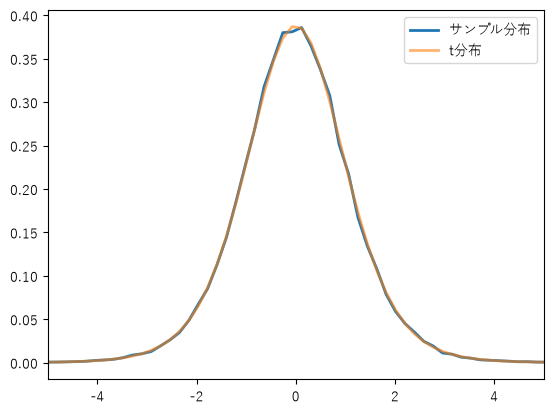

In [27]:
mu = 0.0
n = 10
samples = stats.norm(mu).rvs(size=(100000, n))  #❶
t_samples = (np.mean(samples, axis=1) - mu) / (
    np.std(samples, ddof=1, axis=1) / n**0.5
)  #❷
sample_dist, x = np.histogram(t_samples, bins=100, density=True)  #❸
x = 0.5 * (x[:-1] + x[1:])
t_dist = stats.t(n - 1).pdf(x)
print("max error={:6.4f}".format(np.max(np.abs(sample_dist - t_dist))))

plt.plot(x, sample_dist, lw=2, label="サンプル分布")
plt.plot(x, t_dist, lw=2, alpha=0.6, label="t分布")
plt.xlim(-5, 5)
plt.legend(loc="best");

次の図は、自由度 5 と 39 の確率密度関数と生存関数です。自由度が大きくなると、t 分布は正規分布に近づきます。

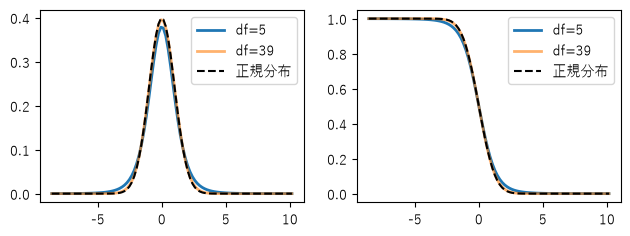

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 2.5))
ax1.plot(x, stats.t(6 - 1).pdf(x), label="df=5", lw=2)
ax1.plot(x, stats.t(40 - 1).pdf(x), label="df=39", lw=2, alpha=0.6)
ax1.plot(x, stats.norm.pdf(x), "k--", label="正規分布")
ax1.legend()

ax2.plot(x, stats.t(6 - 1).sf(x), label="df=5", lw=2)
ax2.plot(x, stats.t(40 - 1).sf(x), label="df=39", lw=2, alpha=0.6)
ax2.plot(x, stats.norm.sf(x), "k--", label="正規分布")
ax2.legend();

t 分布は、標本の平均を検定するのに使えます。平均 1 の正規分布から、30 個の値を取ります。

In [29]:
n = 30
np.random.seed(42)
s = stats.norm.rvs(loc=1, scale=0.8, size=n)

母平均が 0.5 だという帰無仮説を立て、`ttest_1samp()` で棄却できるか調べます。戻り値の 1 番目が $t$ の値、2 番目が $p$ 値です。$p$ 値が 0.05 より小さければ、帰無仮説は成り立たないと判断します。この結果は、母平均が 0.5 という仮説を棄却できることを示しています。

:::{admonition} 帰無仮説
:class: note
帰無仮説(null hypothesis)は、検定で立てる仮説の 1 つです。多くの場合、間違いだと示したい仮説や、ひとまず置いておく仮説です。
:::

In [30]:
t = (np.mean(s) - 0.5) / (np.std(s, ddof=1) / np.sqrt(n))
print(t, stats.ttest_1samp(s, 0.5))

2.658584340882224 TtestResult(statistic=np.float64(2.658584340882224), pvalue=np.float64(0.012637702257091193), df=np.int64(29))


次に、母平均が 1.0 かどうかを検定します。$p$ 値が 0.05 より大きいので、帰無仮説を棄却できません。ただし、これは仮説が正しいという意味ではありません。母平均が 0.9 という仮説でも $p$ 値は 0.05 より大きく、1.0 のときの $t$ より大きくなります。

In [31]:
print((np.mean(s) - 1) / (np.std(s, ddof=1) / np.sqrt(n)))
print(stats.ttest_1samp(s, 1))
print(stats.ttest_1samp(s, 0.9))

-1.1450173670383303
TtestResult(statistic=np.float64(-1.1450173670383303), pvalue=np.float64(0.261564146188015), df=np.int64(29))
TtestResult(statistic=np.float64(-0.3842970254542196), pvalue=np.float64(0.7035619103425201), df=np.int64(29))


`ttest_1samp()` の $p$ 値は、次の図の赤い部分の面積です。$p$ 値の意味はこうです。母平均が仮説の値と同じなら、$n$ 個の値を取ったとき、$t$ の絶対値が標本の $t$ より大きくなる確率が $p$ です。$p$ が小さいほど、仮説が成り立つ見込みは低くなります。逆に $p$ が大きくても、帰無仮説を棄却できないだけで、仮説が正しいとは言えません。

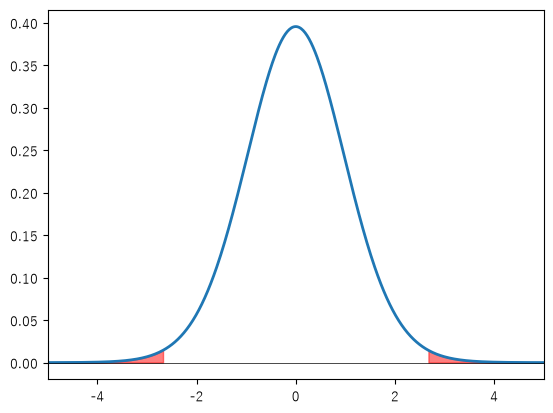

In [32]:
x = np.linspace(-5, 5, 500)
y = stats.t(n - 1).pdf(x)
plt.plot(x, y, lw=2)
t, p = stats.ttest_1samp(s, 0.5)
mask = x > np.abs(t)
plt.fill_between(x[mask], y[mask], color="red", alpha=0.5)
mask = x < -np.abs(t)
plt.fill_between(x[mask], y[mask], color="red", alpha=0.5)
plt.axhline(color="k", lw=0.5)
plt.xlim(-5, 5);

母平均 0.5 の検定を例にします。母平均が本当に 0.5 なら、$t$ が 2.65858 より大きいか -2.65858 より小さい値を取る確率は 0.0126377 です。この確率が小さいので、母平均は 0.5 ではないと判断できます。

$p$ 値を積分で確かめます。左右の赤い部分の面積は等しいので、片側だけ計算して 2 倍します。

In [33]:
from scipy import integrate

x = np.linspace(-10, 10, 100000)
y = stats.t(n - 1).pdf(x)
mask = x >= np.abs(t)
integrate.trapezoid(y[mask], x[mask]) * 2

np.float64(0.012633433707685974)

乱数でも $p$ 値を確かめられます。$m$ 組の乱数を作り、各組で母平均 0.5 と仮定したときの $t$ を計算します。その絶対値が標本の $t$ より大きい組の割合が、$p$ 値になります。

In [34]:
m = 200000
mean = 0.5
r = stats.norm.rvs(loc=mean, scale=0.8, size=(m, n))
ts = (np.mean(s) - mean) / (np.std(s, ddof=1) / np.sqrt(n))
tr = (np.mean(r, axis=1) - mean) / (np.std(r, ddof=1, axis=1) / np.sqrt(n))
np.mean(np.abs(tr) > np.abs(ts))

np.float64(0.012695)

`s1` と `s2` が正規分布の母集団から独立に取った標本なら、`ttest_ind()` で 2 つの母平均に差があるかを検定できます。`equal_var` で、2 つの母集団の分散が同じかを指定します。

次の例では、❶ `s1` と `s2` は分散の違う母集団から来ているので、`equal_var=False` です。$p<0.05$ なので、母平均に差があると判断できます。❷ `s2` と `s3` は同じ分散の母集団から来ているので、`equal_var=True` です。$p$ 値が非常に大きいので、母平均が同じという帰無仮説は棄却できません。

In [35]:
np.random.seed(42)

s1 = stats.norm.rvs(loc=1, scale=1.0, size=20)
s2 = stats.norm.rvs(loc=1.5, scale=0.5, size=20)
s3 = stats.norm.rvs(loc=1.5, scale=0.5, size=25)

print(stats.ttest_ind(s1, s2, equal_var=False))  #❶
print(stats.ttest_ind(s2, s3, equal_var=True))  #❷

TtestResult(statistic=np.float64(-2.2391470627176755), pvalue=np.float64(0.033250866086743706), df=np.float64(28.072969108063))
TtestResult(statistic=np.float64(-0.5946698521856172), pvalue=np.float64(0.555180587581054), df=np.float64(43.0))


## カイ二乗分布とカイ二乗検定

カイ二乗分布($\chi ^{2}$)も、統計でよく使う分布です。$k$ 個の独立な標準正規変数の二乗和は、自由度 $k$ のカイ二乗分布に従います。乱数で確かめます。

max error: 0.0031


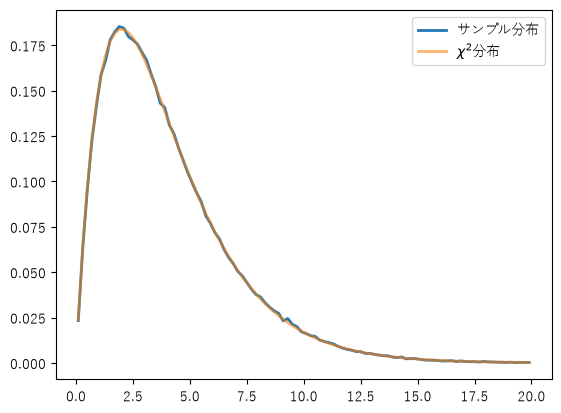

In [36]:
a = np.random.normal(size=(300000, 4))
cs = np.sum(a**2, axis=1)

sample_dist, bins = np.histogram(cs, bins=100, range=(0, 20), density=True)
x = 0.5 * (bins[:-1] + bins[1:])
chi2_dist = stats.chi2.pdf(x, 4)
print("max error: {:6.4f}".format(np.max(np.abs(sample_dist - chi2_dist))))

plt.plot(x, sample_dist, lw=2, label="サンプル分布")
plt.plot(x, chi2_dist, lw=2, alpha=0.6, label=r"$\chi ^{2}$分布")
plt.legend(loc="best");

カイ二乗分布は、次のような現象にも当てはまります。袋に 5 色のボールが同じ数だけ入っていて、$N$ 回取り出して色ごとの回数 $O_i$ を数えます。このとき、次の $\chi^2$ は自由度 4 のカイ二乗分布に従います。$E=N/5$ は、各色の期待回数です。

$$\chi^2 = \sum_{i=1}^{k}{\frac{(O_i-E)^2}{E}}$$

次のコードでシミュレーションします。❶ `randint()` で 0 から 4 の乱数を作ります。行が実験、列が 1 回に取り出す 100 個のボールです。❷ `bincount()` で色ごとの回数を数えます。`bincount()` は多次元に対応していないので、`apply_along_axis()` で行ごとに呼びます。`minlength=5` で、結果の長さをそろえます。❸ 上の式で $\chi^2$ を計算し、❹ `gaussian_kde()` でその分布を推定します。

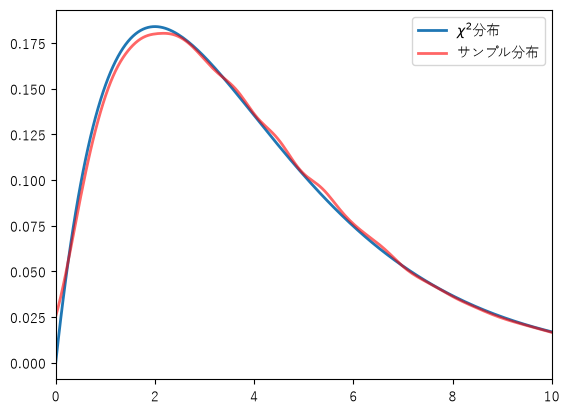

In [37]:
repeat_count = 60000
n, k = 100, 5

np.random.seed(42)
ball_ids = np.random.randint(0, k, size=(repeat_count, n))  #❶
counts = np.apply_along_axis(np.bincount, 1, ball_ids, minlength=k)  #❷
cs2 = np.sum((counts - n / k) ** 2.0 / (n / k), axis=1)  #❸
k = gaussian_kde(cs2)
x = np.linspace(0, 10, 200)
plt.plot(x, stats.chi2.pdf(x, 4), lw=2, label=r"$\chi ^{2}$分布")
plt.plot(x, k(x), lw=2, color="red", alpha=0.6, label="サンプル分布")
plt.legend(loc="best")
plt.xlim(0, 10);

カイ二乗検定は、観測値と理論値の差が、偶然のばらつきで説明できるかを調べます。

次の例では、袋のボールの色の確率を `probabilities` で指定します。`choose_balls(probabilities, size)` は、袋から `size` 回取り出して、色ごとの回数を返します。袋 1 の確率は 0.18、0.24、0.25、0.16、0.17 で、袋 2 は 5 色とも同じです。それぞれ取り出した結果が `counts1` と `counts2` です。この 2 つの袋が均等かどうかを調べます。

In [38]:
def choose_balls(probabilities, size):
    s = stats.rv_discrete(values=(range(len(probabilities)), probabilities)).rvs(
        size=size
    )
    counts = np.bincount(s)
    return counts


np.random.seed(42)
counts1 = choose_balls([0.18, 0.24, 0.25, 0.16, 0.17], 400)
counts2 = choose_balls([0.2] * 5, 400)

%C counts1; counts2

      counts1               counts2       
--------------------  --------------------
[80, 93, 97, 64, 66]  [89, 76, 79, 71, 85]


`chisquare()` でカイ二乗検定を行います。引数は色ごとの回数です。目標の確率を渡さなければ、均等分布かどうかを検定します。帰無仮説は「サンプルが目標の確率に従う」です。

袋 1 の $p$ 値は 0.02 でした。均等分布なら、この結果が出る確率は 2% しかありません。したがって帰無仮説を棄却でき、袋 1 は均等とは言えません。袋 2 の $p$ 値は 0.64 で、帰無仮説を棄却できません。ただし、これは袋 2 が均等だと証明できたわけではありません。

In [39]:
chi1, p1 = stats.chisquare(counts1)
chi2, p2 = stats.chisquare(counts2)

print("chi1 = {:7.4f} p1 = {:6.4f}".format(chi1, p1))
print("chi1 = {:7.4f} p1 = {:6.4f}".format(chi2, p2))

chi1 = 11.3750 p1 = 0.0227
chi1 =  2.5500 p1 = 0.6357


カイ二乗検定は、カイ二乗分布の面積で $p$ 値を計算します。次の図は自由度 4 のカイ二乗分布で、$\chi_1^2$ と $\chi_2^2$ の位置を示しています。$p_1$ が $\chi_1^2$ より右の面積、$p_2$ が $\chi_2^2$ より右の面積です。

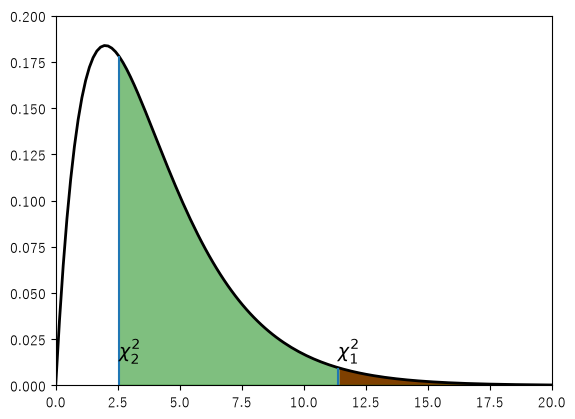

In [40]:
x = np.linspace(0, 30, 200)
CHI2 = stats.chi2(4)
plt.plot(x, CHI2.pdf(x), "k", lw=2)
plt.vlines(chi1, 0, CHI2.pdf(chi1))
plt.vlines(chi2, 0, CHI2.pdf(chi2))
plt.fill_between(x[x > chi1], 0, CHI2.pdf(x[x > chi1]), color="red", alpha=1.0)
plt.fill_between(x[x > chi2], 0, CHI2.pdf(x[x > chi2]), color="green", alpha=0.5)
plt.text(chi1, 0.015, r"$\chi^2_1$", fontsize=14)
plt.text(chi2, 0.015, r"$\chi^2_2$", fontsize=14)
plt.ylim(0, 0.2)
plt.xlim(0, 20);

カイ二乗検定は、2 次元のデータにも使えます。サンプルを 2 つの属性で分けた表を、分割表と呼びます。次の表は、性別と利き手の分割表です。この結果から、性別と利き手に関連があるかを調べます。

| 　  | 右手  |  左手 |
| :-- | :-- | :-- |
| 男性  | 43  |  9 |
| 女性  | 44  |  4 |

`chi2_contingency()` で検定します。帰無仮説は「性別と利き手に関連がない」、つまり男女で左右の手を使う確率が同じという仮説です。$p$ 値は 0.3 なので、帰無仮説は棄却できません。このデータからは、男女の利き手に違いがあるとは言えません。

In [41]:
table = [[43, 9], [44, 4]]
chi2, p, dof, expected = stats.chi2_contingency(table)
%C chi2; p

             chi2                             p              
------------------------------  -----------------------------
np.float64(1.0724852071005921)  np.float64(0.300384770390566)


2×2 の小さな分割表では、`fisher_exact()` で正確な $p$ 値を計算できます。

In [42]:
stats.fisher_exact(table)

SignificanceResult(statistic=np.float64(0.43434343434343436), pvalue=np.float64(0.2391569568222429))

## まとめ

* 確率変数は `stats` のオブジェクトで、`pdf`、`cdf`、`rvs`、`stats`、`fit` などのメソッドを持つ。
* 乱数のヒストグラムと確率密度関数を比べると、分布の式を確かめられる。
* 離散分布は `rv_discrete` で自分で作れる。中心極限定理は、平均の分布が正規分布に近づくことを示す。
* 二項分布は $n$ が大きく $p$ が小さいときポアソン分布で近似でき、事象の間隔はガンマ分布に従う。
* t 検定は標本の平均を比べる。$p$ 値が小さければ帰無仮説を棄却できるが、棄却できないことは仮説の証明ではない。
* カイ二乗検定は、度数の偏りや分割表の関連を調べる。2×2 の表では `fisher_exact()` も使える。